# Fraud experiments in PyTorch
Run cells sequentially. Every intermediate object is editable. Fit transformations only on training data; reserve test data for final evaluation. Re-run downstream cells after changing an earlier stage.

In [ ]:
from pathlib import Path
import sys

if Path("experiment").is_dir():
    sys.path.insert(0, str(Path("experiment").resolve()))
from fraud_torch import *
import matplotlib.pyplot as plt

config = Config()
config

Config(train_input='/Users/nguyencongkhanh/Documents/Lecture/Programming III/GoLang/go_neural_network/credit-card-fraud-datasets/transactions_train_split.csv', validation_input='/Users/nguyencongkhanh/Documents/Lecture/Programming III/GoLang/go_neural_network/credit-card-fraud-datasets/transactions_validation.csv', test_input='/Users/nguyencongkhanh/Documents/Lecture/Programming III/GoLang/go_neural_network/credit-card-fraud-datasets/transactions_test.csv', train_size=200000, validation_size=50000, test_size=50000, epochs=3, batch_size=256, learning_rate=0.001, hidden=64, hidden2=32, optimizer='adam', positive_weight='auto', seed=42, device='cpu', output='/Users/nguyencongkhanh/Documents/Lecture/Programming III/GoLang/go_neural_network/experiment/runs')

## Load representative samples
Sampling scans the source files. Keep these frames in memory while trying different training settings.

In [ ]:
frames = {
    name: load_sample(
        getattr(config, name + "_input"), getattr(config, name + "_size"), config.seed
    )
    for name in ["train", "validation", "test"]
}
pd.DataFrame(
    {k: {"rows": len(v), "fraud": int(v.isFraud.sum())} for k, v in frames.items()}
)

transactions_train_split.csv: 200000 rows, 243 fraud
transactions_validation.csv: 50000 rows, 61 fraud
transactions_test.csv: 50000 rows, 61 fraud


,train,validation,test
rows,200000,50000,50000
fraud,243,61,61


## Preprocess and scale
Edit the frames here before fitting the training scaler. Balance columns are intentionally ignored.

In [ ]:
frames = {k: preprocess(v) for k, v in frames.items()}
scaler = fit_scaler(frames["train"])
print("Training log-amount mean/scale:", scaler.mean_, scaler.scale_)

Training log-amount mean/scale: [10.84434085] [1.8152803]


## Feature engineering
Inspect or edit the feature matrices here. Changing width also requires changing the first model layer and the checkpoint feature contract.

In [ ]:
x = {k: build_features(v, scaler) for k, v in frames.items()}
y = {k: v.isFraud.to_numpy() for k, v in frames.items()}
x["train"].head()

,log_amount_z,transfer_amount,cashout_amount,hour_sin,hour_cos,type_PAYMENT,type_TRANSFER,type_CASH_OUT,type_DEBIT,type_CASH_IN,dest_is_merchant
10,-0.816727,-0.0,-0.0,0.258819,0.965926,1.0,0.0,0.0,0.0,0.0,1.0
14,-1.993382,-0.0,-0.0,0.258819,0.965926,1.0,0.0,0.0,0.0,0.0,1.0
26,-1.602880,-0.0,-0.0,0.258819,0.965926,1.0,0.0,0.0,0.0,0.0,1.0
45,-1.642114,-0.0,-0.0,0.258819,0.965926,1.0,0.0,0.0,0.0,0.0,1.0
52,-1.563557,-0.0,-0.0,0.258819,0.965926,1.0,0.0,0.0,0.0,0.0,1.0


## Model and optimizer
Replace these standard PyTorch objects to experiment. Calling the training cell again continues from the current weights and optimizer state.

In [ ]:
assert (
    len(np.unique(y["train"])) == 2 and y["validation"].sum() > 0
), "Increase sample sizes"
weight = (
    float((y["train"] == 0).sum() / y["train"].sum())
    if config.positive_weight == "auto"
    else float(config.positive_weight)
)
model = build_model(config)
optimizer = build_optimizer(model, config)
loader = make_loader(x["train"], y["train"], config.batch_size, config.seed)
history = []
model

Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)

1 train BCE 0.4413373217758463 AP 0.2829764055968792
1 validation BCE 0.4401134084582526 AP 0.22164922089268774
2 train BCE 0.33363112872670075 AP 0.19265909989553118
2 validation BCE 0.3328113874467752 AP 0.1436205637611837
3 train BCE 0.2888501015210386 AP 0.2512942113568468
3 validation BCE 0.2882360435027716 AP 0.18726656464364203


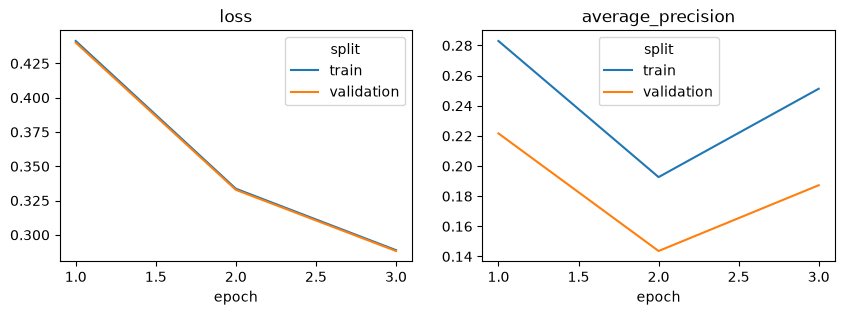

In [ ]:
start_epoch = max([r["epoch"] for r in history], default=0)
for epoch in range(start_epoch + 1, start_epoch + config.epochs + 1):
    train_epoch(model, loader, optimizer, weight)
    for name in ["train", "validation"]:
        metrics = evaluate(y[name], predict(model, x[name]), positive_weight=weight)
        history.append(dict(epoch=epoch, split=name, **metrics))
        print(epoch, name, "BCE", metrics["loss"], "AP", metrics["average_precision"])
history_frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for metric, ax in zip(["loss", "average_precision"], axes):
    history_frame.pivot(index="epo ch", columns="split", values=metric).plot(
        ax=ax, title=metric
    )
plt.show()

## Validation threshold, then final test evaluation

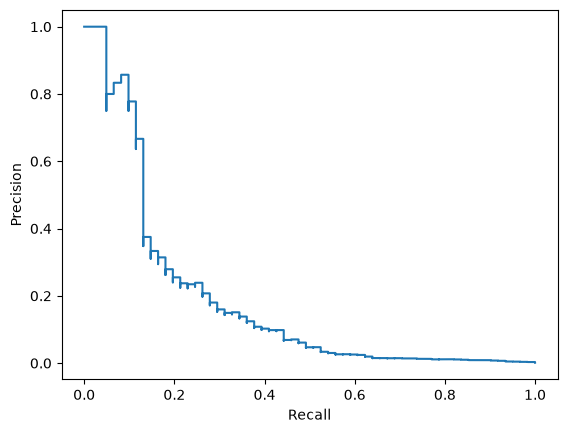

Selected threshold: 0.9599881768226624


,threshold,precision,recall,f2
0,0.10,0.002818,1.000000,0.013934
1,0.20,0.002833,1.000000,0.014005
2,0.30,0.003546,0.983607,0.017479
3,0.40,0.004775,0.934426,0.023397
4,0.50,0.007806,0.901639,0.037723
5,0.60,0.012017,0.770492,0.056558
6,0.70,0.019669,0.622951,0.087316
7,0.75,0.026297,0.590164,0.111593
8,0.80,0.031670,0.540984,0.128305


,train,validation,test
loss,0.28885,0.288236,0.28454
weighted_bce,0.566516,0.580616,0.639798
average_precision,0.251294,0.187267,0.256756
accuracy,0.99707,0.99684,0.99718
precision,0.182994,0.151079,0.205882
recall,0.407407,0.344262,0.459016
f1,0.252551,0.21,0.284264
f2,0.327165,0.274151,0.368421
true_pos,99,21,28
false_pos,442,118,108


In [ ]:
probabilities = {k: predict(model, v) for k, v in x.items()}
threshold = select_threshold(y["validation"], probabilities["validation"])
final = {
    k: evaluate(y[k], p, threshold, weight, True) for k, p in probabilities.items()
}
threshold_table = pd.DataFrame(
    [
        evaluate(y["validation"], probabilities["validation"], t, weight)
        for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8]
    ]
)
precision, recall, _ = precision_recall_curve(
    y["validation"], probabilities["validation"]
)
plt.step(recall, precision, where="post")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()
print("Selected threshold:", threshold)
display(threshold_table[["threshold", "precision", "recall", "f2"]])
display(pd.DataFrame(final).drop(index="probability_stats"))

## Record this experiment and reload predictions
Use a fresh directory for each experiment. The checkpoint records the standard feature contract; edit serialization too if you change that contract.

In [ ]:
directory = Path(config.output) / str(time.time_ns())
directory.mkdir(parents=True)
history_frame.to_csv(directory / "history.csv", index=False)
threshold_table.to_csv(directory / "validation_thresholds.csv", index=False)
(directory / "metrics.json").write_text(json.dumps(final, indent=2, allow_nan=False))
(directory / "config.json").write_text(
    json.dumps(
        dict(
            config=asdict(config),
            positive_weight=weight,
            python=platform.python_version(),
            torch=str(torch.__version__),
        ),
        indent=2,
    )
)
np.savez_compressed(
    directory / "sample_indices.npz",
    **{k: f.index.to_numpy() for k, f in frames.items()}
)
save_checkpoint(directory / "model.pt", model, optimizer, scaler, threshold, config)
restored, restored_optimizer, restored_scaler, cutoff, saved_config = load_checkpoint(
    directory / "model.pt"
)
example = frames["test"].head()
scores = predict(restored, build_features(example, restored_scaler))
display(
    example.assign(probability=scores, predicted_fraud=(scores >= cutoff).astype(int))
)
print(directory)

,step,type,amount,nameDest,isFraud,probability,predicted_fraud
6,1,PAYMENT,4910.14,M589987187,0,0.000503,0
7,1,PAYMENT,2131.84,M61073295,0,0.000638,0
14,1,CASH_OUT,467177.03,C1170794006,0,0.978679,1
52,1,PAYMENT,6049.09,M314364096,0,0.000500,0
63,1,CASH_IN,155075.41,C1971489295,0,0.005394,0


/Users/nguyencongkhanh/Documents/Lecture/Programming III/GoLang/go_neural_network/experiment/runs/1794515146009214000
